# **Actividad | Dataset - Notebook**
### Mónica María Ramírez Mejía
### A01797493

In [1]:
import os
import kagglehub
import pandas as pd

# Descargar el dataset desde Kaggle
path = kagglehub.dataset_download("sakshigoyal7/credit-card-customers")

# Leer el archivo CSV
df = pd.read_csv(os.path.join(path, "BankChurners.csv"))

# Vista preliminar de la base
df.head()

c:\Users\monic\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


**1. Carga y descripción del dataset**

        Revisión del tamaño, tipos de daros y caracteristicas principales del conjunto de datos.

In [2]:
# Número de registros y columnas
print("Filas y columnas:", df.shape)

Filas y columnas: (10127, 23)


In [3]:
# Tipos de datos y valores no nulos de cada variable
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  str    
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                                      

In [4]:
df.dtypes

CLIENTNUM                                                                                                                               int64
Attrition_Flag                                                                                                                            str
Customer_Age                                                                                                                            int64
Gender                                                                                                                                    str
Dependent_count                                                                                                                         int64
Education_Level                                                                                                                           str
Marital_Status                                                                                                                            str
Income

In [5]:
# Resumen estadístico de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CLIENTNUM,10127.0,7.391776e+08,3.690378e+07,7.080821e+08,7.130368e+08,7.179264e+08,7.731435e+08,8.283431e+08
Customer_Age,10127.0,4.632596e+01,8.016814e+00,2.600000e+01,4.100000e+01,4.600000e+01,5.200000e+01,7.300000e+01
Dependent_count,10127.0,2.346203e+00,1.298908e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00
Months_on_book,10127.0,3.592841e+01,7.986416e+00,1.300000e+01,3.100000e+01,3.600000e+01,4.000000e+01,5.600000e+01
Total_Relationship_Count,10127.0,3.812580e+00,1.554408e+00,1.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00
Months_Inactive_12_mon,10127.0,2.341167e+00,1.010622e+00,0.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
Contacts_Count_12_mon,10127.0,2.455317e+00,1.106225e+00,0.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
Credit_Limit,10127.0,8.631954e+03,9.088777e+03,1.438300e+03,2.555000e+03,4.549000e+03,1.106750e+04,3.451600e+04
Total_Revolving_Bal,10127.0,1.162814e+03,8.149873e+02,0.000000e+00,3.590000e+02,1.276000e+03,1.784000e+03,2.517000e+03
Avg_Open_To_Buy,10127.0,7.469140e+03,9.090685e+03,3.000000e+00,1.324500e+03,3.474000e+03,9.859000e+03,3.451600e+04


**2. Analisis exploratorio EDA**
        
        Se analizan las variables para identificar patrones.

Distribución de la variable obejtivo

Distribución de clientes:
                   Cantidad  Porcentaje
Attrition_Flag                         
Existing Customer      8500       83.93
Attrited Customer      1627       16.07


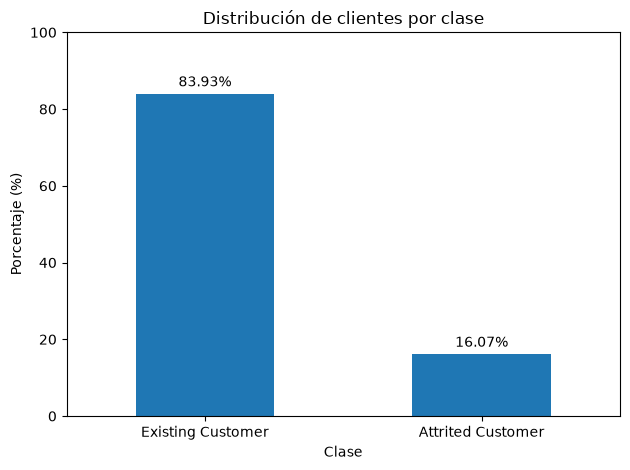

In [6]:
import matplotlib.pyplot as plt

# Conteo y porcentaje de cada clase
resumen = df["Attrition_Flag"].value_counts().to_frame("Cantidad")
resumen["Porcentaje"] = (
    df["Attrition_Flag"].value_counts(normalize=True) * 100
).round(2)

print("Distribución de clientes:")
print(resumen)

# Gráfico
ax = resumen["Porcentaje"].plot(kind="bar")

plt.title("Distribución de clientes por clase")
plt.xlabel("Clase")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

for i, porcentaje in enumerate(resumen["Porcentaje"]):
    ax.text(i, porcentaje + 2, f"{porcentaje:.2f}%", ha="center")

plt.tight_layout()
plt.show()

Se observa desbalance en las clases, dado que solo el 16% de registros de la base, muestran que un cliente canceló. Por tal razón, debemos revisar accuracy, recall y F1 score en la evaluación del modelo.

Análisis de otras variables

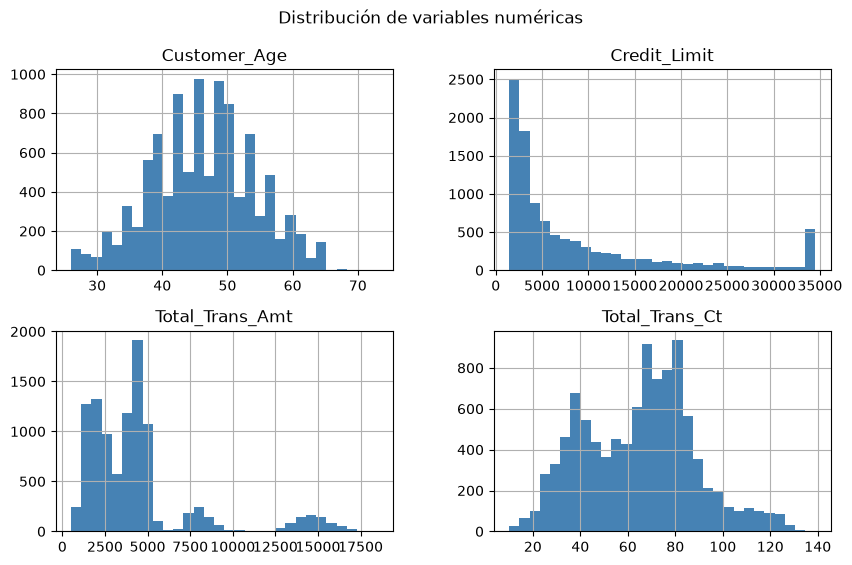

In [7]:
# Edad, límite de crédito y actividad transaccional
columnas = ["Customer_Age", "Credit_Limit", "Total_Trans_Amt", "Total_Trans_Ct"]
df[columnas].hist(bins=30, figsize=(10, 6), color="steelblue")
plt.suptitle("Distribución de variables numéricas")
plt.show()

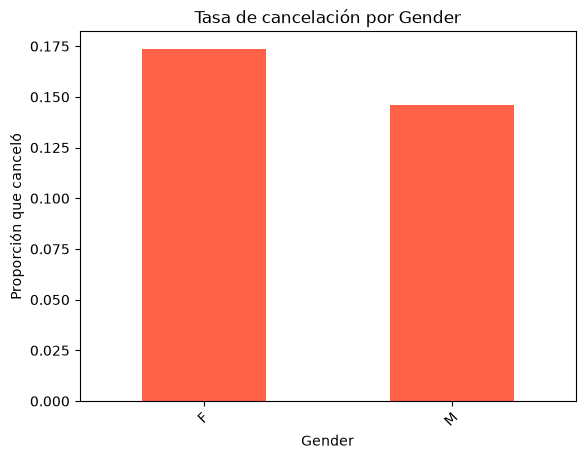

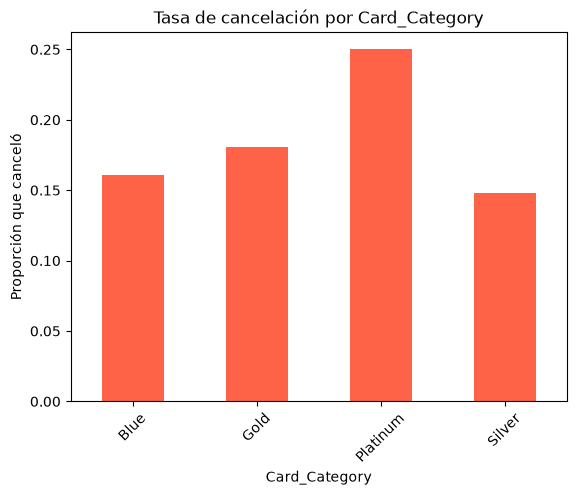

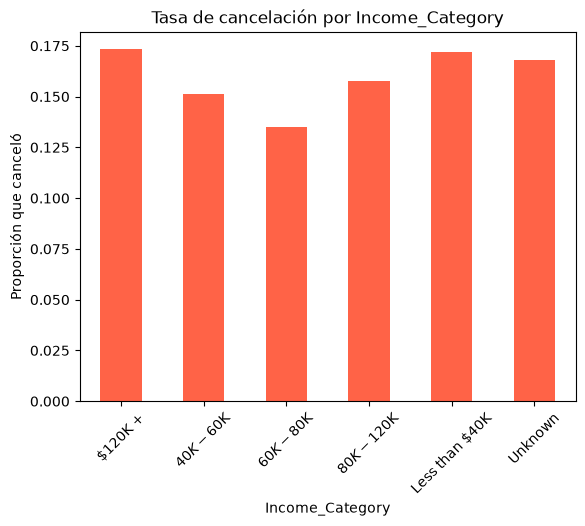

In [8]:
# Clientes que cancelaron
for col in ["Gender", "Card_Category", "Income_Category"]:
    tasa = df.groupby(col)["Attrition_Flag"].apply(lambda x: (x == "Attrited Customer").mean())
    tasa.plot(kind="bar", color="tomato")
    plt.title(f"Tasa de cancelación por {col}")
    plt.ylabel("Proporción que canceló")
    plt.xticks(rotation=45)
    plt.show()

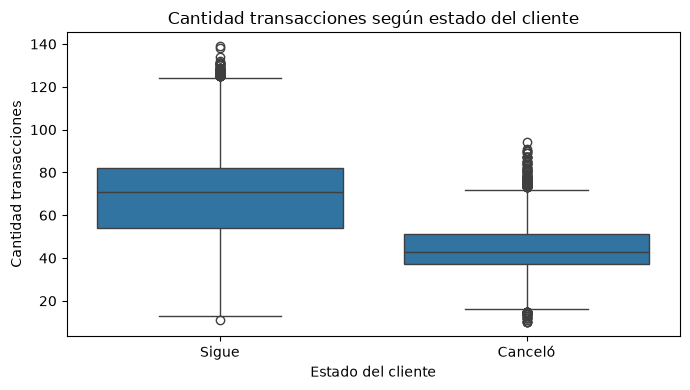

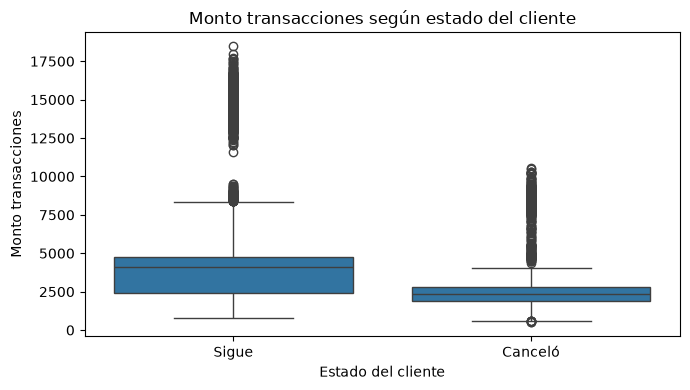

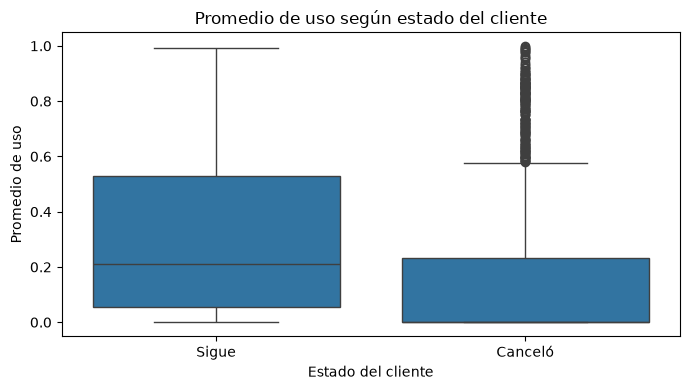

In [9]:
import seaborn as sns

# Boxplots: comparacion de variables segun el estado del cliente
grupos = [
    ("Total_Trans_Ct", "Cantidad transacciones"),
    ("Total_Trans_Amt", "Monto transacciones"),
    ("Avg_Utilization_Ratio", "Promedio de uso")
]

for col, titulo in grupos:
    plt.figure(figsize=(7, 4))
    
    sns.boxplot(
        data=df,
        x="Attrition_Flag",
        y=col
    )
    
    plt.title(f"{titulo} según estado del cliente")
    plt.xlabel("Estado del cliente")
    plt.ylabel(titulo)
    plt.xticks(
        [0, 1],
        ["Sigue", "Canceló"]
    )
    plt.tight_layout()
    plt.show()

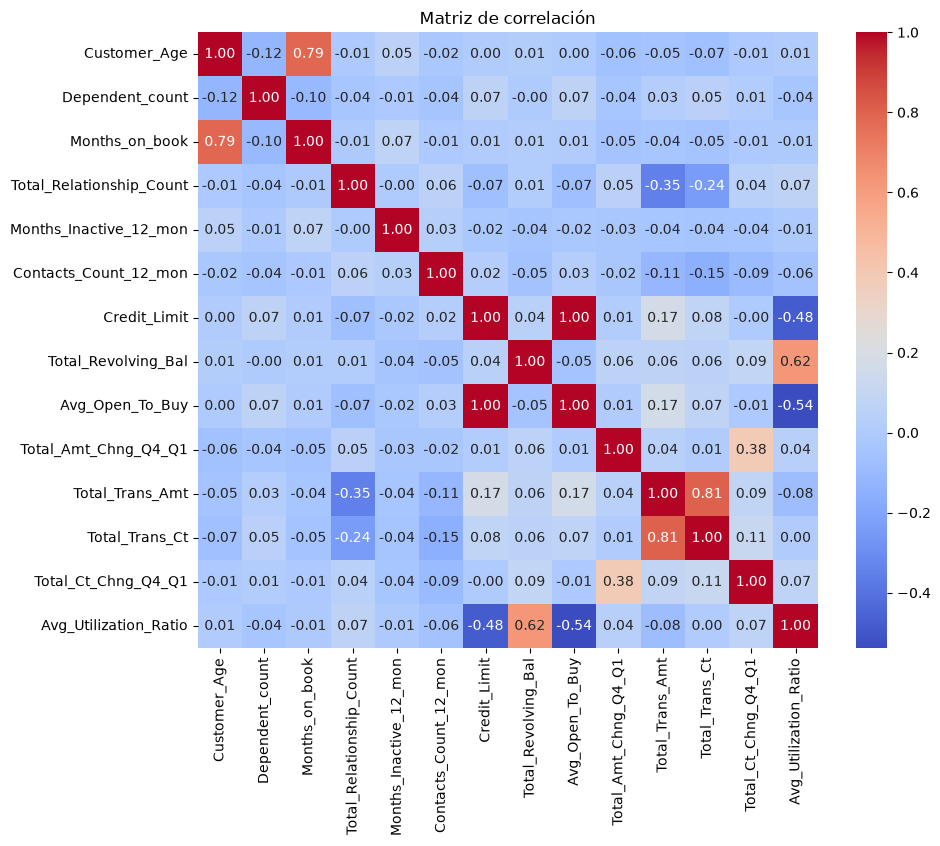

In [10]:
# Matriz de correlación
numericas = df.select_dtypes(include="number").drop(columns=["CLIENTNUM"])
numericas = numericas[[c for c in numericas.columns if not c.startswith("Naive_Bayes")]]

plt.figure(figsize=(10, 8))
sns.heatmap(numericas.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

**Conclusión del EDA:** La edad se concentra entre 40 y 55 años, mientras que el límite de crédito se concentra en valores bajos y presenta una cola hacia valores altos. La tasa de cancelación es mayor en tarjetas Platinum. Los boxplots muestran que los clientes que conservan su tarjeta suelen realizar más transacciones, con mayores montos y presentan mayor uso de la tarjeta. Finalmente, la correlación evidencia relaciones fuertes, principalmente entre Credit_Limit y Avg_Open_To_Buy con 0.996.

**3. Limpieza de datos**

        Revisión de valores nulos, duplicados, valores atipicos y variables que no aportan al analisis.

In [11]:
# Contar valores nulos por columna
df.isnull().sum().sum()

np.int64(0)

In [12]:
# Otra forma de nulos
for col in ["Education_Level", "Marital_Status", "Income_Category"]:
    cantidad = (df[col] == "Unknown").sum()
    porcentaje = cantidad / len(df) * 100
    print(col, "->", cantidad, f"-> {porcentaje:.2f}%")

Education_Level -> 1519 -> 15.00%
Marital_Status -> 749 -> 7.40%
Income_Category -> 1112 -> 10.98%


Esta base, en particular, no tiene valores nulos. Pero, tres de sus columnas contienen "Unknown". Por lo que, se dejarán como una categoría más, debido que si se eliminan, se estarán perdiendo una gran cantidad de registros con información relevante. 

In [13]:
# Duplicados
print("Duplicados:", df.duplicated().sum())

# Duplicados clientes (ID)
print("IDs repetidos:", df["CLIENTNUM"].duplicated().sum())

Duplicados: 0
IDs repetidos: 0


In [14]:
# Eliminar columnas que no son útiles para el análisis
# ID y Naive_Bayes
columnas_naive = [c for c in df.columns if c.startswith("Naive_Bayes")]
df_limpio = df.drop(columns=["CLIENTNUM"] + columnas_naive)

# Avg_Open_To_Buy
print("Correlación Credit_Limit vs Avg_Open_To_Buy:",
      round(df["Credit_Limit"].corr(df["Avg_Open_To_Buy"]), 3))
df_limpio = df_limpio.drop(columns=["Avg_Open_To_Buy"])

df_limpio.shape

Correlación Credit_Limit vs Avg_Open_To_Buy: 0.996


(10127, 19)

La columna de CLIENTNUM es solo un identificador. Naive_Bayes es una variable que aparece en la base, pero es de otro modelo; por lo que no es conveniente conservarla. Avg_Open_To_Buy se elimina porque tiene una correlación muy alta con Credit_Limit.

In [15]:
# Valores atipicos
# Contar outliers con el método del rango intercuartil (IQR)
numericas = df_limpio.select_dtypes(include="number")

for col in numericas.columns:
    q1 = numericas[col].quantile(0.25)
    q3 = numericas[col].quantile(0.75)
    iqr = q3 - q1
    n_outliers = ((numericas[col] < q1 - 1.5 * iqr) | (numericas[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_outliers} outliers")

Customer_Age: 2 outliers
Dependent_count: 0 outliers
Months_on_book: 386 outliers
Total_Relationship_Count: 0 outliers
Months_Inactive_12_mon: 331 outliers
Contacts_Count_12_mon: 629 outliers
Credit_Limit: 984 outliers
Total_Revolving_Bal: 0 outliers
Total_Amt_Chng_Q4_Q1: 396 outliers
Total_Trans_Amt: 896 outliers
Total_Trans_Ct: 2 outliers
Total_Ct_Chng_Q4_Q1: 394 outliers
Avg_Utilization_Ratio: 0 outliers


Se utiliza el rango intercuartil (IQR) para identificar los outliers.
Se conservarán los outliers, se puede apreciar que, son clientes reales (por ejemplo, personas con límites de crédito muy altos) y no parecen ser errores en la recoleccion de la información.

In [16]:
# Conversión de la variable objetivo a 0 y 1 (1 = el cliente canceló)
df_limpio["Attrition_Flag"] = (df_limpio["Attrition_Flag"] == "Attrited Customer").astype(int)

# Conversión de columnas de texto a tipo "category"
for col in df_limpio.select_dtypes(include="object").columns:
    df_limpio[col] = df_limpio[col].astype("category")

df_limpio.dtypes

C:\Users\monic\AppData\Local\Temp\ipykernel_4132\223686436.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_limpio.select_dtypes(include="object").columns:


Attrition_Flag                 int64
Customer_Age                   int64
Gender                      category
Dependent_count                int64
Education_Level             category
Marital_Status              category
Income_Category             category
Card_Category               category
Months_on_book                 int64
Total_Relationship_Count       int64
Months_Inactive_12_mon         int64
Contacts_Count_12_mon          int64
Credit_Limit                 float64
Total_Revolving_Bal            int64
Total_Amt_Chng_Q4_Q1         float64
Total_Trans_Amt                int64
Total_Trans_Ct                 int64
Total_Ct_Chng_Q4_Q1          float64
Avg_Utilization_Ratio        float64
dtype: object

La variable objetivo se transforma en valores 0 y 1, para facilitar el entrenamiento del modelo. Además, las variables de texto se convierten a category porque representan variables categóricas.